# Exploratory data analysis of the BGL log dataset

## 0. Setup

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display

SMOKE_TEST = False   # must match the setting used in 01_pipeline.ipynb
TRAIN_FRAC, VAL_FRAC = 0.7, 0.15   # same 70/15/15 split as the pipeline
SEED = 42

ROOT = Path.cwd()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT_ROOT = ROOT / "smoke" if SMOKE_TEST else ROOT
INTERIM, PROCESSED = OUT_ROOT / "data" / "interim", OUT_ROOT / "data" / "processed"
FIG, TABLES = OUT_ROOT / "reports" / "figures", OUT_ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#2b5d73", "#a8501f", "#8a8a8a"
LEVEL_COLORS = {"INFO": "#9fb7c4", "WARNING": "#e3c16f", "ERROR": "#d98b5f", "SEVERE": "#c4622d",
                "FATAL": "#8c1c13", "FAILURE": "#4a0d08"}

def date_axis(ax):
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

def save(fig, name):
    """Save a figure for the report and show it here."""
    fig.tight_layout()
    fig.savefig(FIG / f"eda_{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def save_table(df, name, index=True):
    df.to_csv(TABLES / f"eda_{name}.csv", index=index)
    return df

def load_table(path):
    df = pd.read_csv(path, keep_default_na=False)
    for col in ("tokens", "lemmas"):
        if col in df:
            df[col] = df[col].map(json.loads)
    return df

KEY = {}   # key numbers collected along the way for section 10

In [2]:
lines = pd.read_parquet(INTERIM / "bgl_parsed.parquet",
                        columns=["line_id", "label", "is_anomaly", "ts", "node", "component", "level",
                                 "cluster_id", "msg_id"])
lines = lines.sort_values(["ts", "line_id"], kind="stable").reset_index(drop=True)
lines["time"] = pd.to_datetime(lines["ts"], unit="s")
templates = load_table(INTERIM / "templates_nlp.csv")
messages = load_table(INTERIM / "messages_nlp.csv")
parse_stats = json.loads((INTERIM / "parse_stats.json").read_text())
meta = pd.read_parquet(PROCESSED / "windows.parquet")
W_template = sp.load_npz(PROCESSED / "W_template.npz").tocsr()
print(f"{len(lines):,} lines | {len(templates):,} templates | {len(messages):,} masked messages | {len(meta):,} windows")

4,747,963 lines | 392 templates | 16,107 masked messages | 14,501 windows


## 1. Dataset summary

In [3]:
span_days = (lines["ts"].max() - lines["ts"].min()) / 86400
overview = pd.Series({
    "log lines": len(lines),
    "malformed lines skipped": parse_stats["malformed"],
    "first entry": lines["time"].min(),
    "last entry": lines["time"].max(),
    "days spanned": round(span_days, 1),
    "alert lines": int(lines["is_anomaly"].sum()),
    "alert line rate": f'{lines["is_anomaly"].mean():.2%}',
    "alert categories": lines.loc[lines["is_anomaly"], "label"].nunique(),
    "distinct nodes": lines["node"].nunique(),
    "components": lines["component"].nunique(),
    "severity levels": lines["level"].nunique(),
    "Drain3 templates": len(templates),
    "masked messages (parser-free)": len(messages),
    "5-minute windows (non-empty)": len(meta),
}, name="value").to_frame()
KEY.update({"lines": len(lines), "alert_lines": int(lines["is_anomaly"].sum()), "days": round(span_days, 1),
            "nodes": lines["node"].nunique(), "templates": len(templates), "masked_messages": len(messages)})
save_table(overview, "overview")

,value
log lines,4747963
malformed lines skipped,0
first entry,2005-06-03 22:42:50
last entry,2006-01-04 16:00:05
days spanned,214.7
alert lines,348460
alert line rate,7.34%
alert categories,41
distinct nodes,69252
components,14


## 2. Labels, severity levels, and components

### 2.1. Alert categories

,lines,share_of_alerts
label,,
KERNDTLB,152734,0.4383
KERNSTOR,63491,0.1822
APPSEV,49651,0.1425
KERNMNTF,31531,0.0905
KERNTERM,23338,0.0670
KERNREC,6145,0.0176
APPREAD,5983,0.0172
KERNRTSP,3983,0.0114
APPRES,2370,0.0068


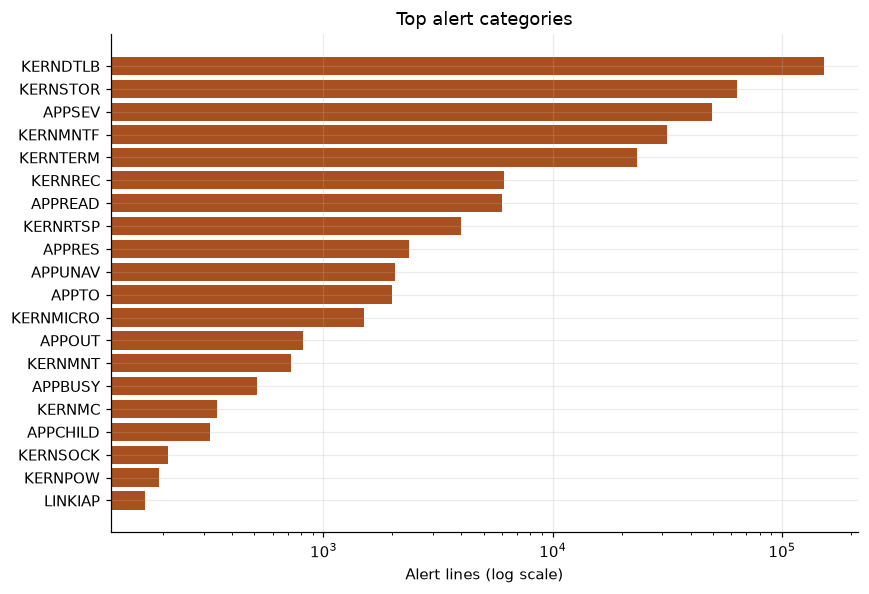

In [4]:
cats = lines.loc[lines["is_anomaly"], "label"].value_counts()
cat_table = pd.DataFrame({"lines": cats, "share_of_alerts": (cats / cats.sum()).round(4)})
save_table(cat_table, "alert_categories")
display(cat_table.head(20))

top = cats.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=ORANGE)
ax.set(xscale="log", xlabel="Alert lines (log scale)", title="Top alert categories")
save(fig, "alert_categories_top20")

### 2.2. Severity level vs label and leakage

is_anomaly,normal,alert,total,alert_rate
level,,,,
INFO,3735813,0,3735813,0.0000
FATAL,506797,348398,855195,0.4074
ERROR,112355,0,112355,0.0000
WARNING,23357,0,23357,0.0000
SEVERE,19213,0,19213,0.0000
FAILURE,1652,62,1714,0.0362
Kill,306,0,306,0.0000
microseconds,4,0,4,0.0000
single,4,0,4,0.0000


Line-level rule 'level is FATAL/FAILURE/SEVERE/ERROR': precision 0.353, recall 1.000


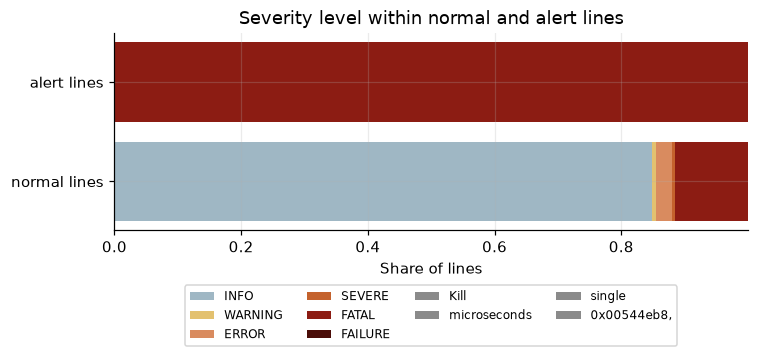

In [5]:
lvl = pd.crosstab(lines["level"], lines["is_anomaly"]).rename(columns={False: "normal", True: "alert"})
lvl["total"] = lvl.sum(axis=1)
lvl["alert_rate"] = (lvl["alert"] / lvl["total"]).round(4)
lvl = lvl.sort_values("total", ascending=False)
save_table(lvl, "level_vs_label")
display(lvl)

severe = lines["level"].isin(["FATAL", "FAILURE", "SEVERE", "ERROR"])
rule_precision = lines.loc[severe, "is_anomaly"].mean() if severe.any() else np.nan
rule_recall = severe[lines["is_anomaly"]].mean() if lines["is_anomaly"].any() else np.nan
KEY.update({"severe_level_precision": round(float(rule_precision), 4), "severe_level_recall": round(float(rule_recall), 4)})
print(f"Line-level rule 'level is FATAL/FAILURE/SEVERE/ERROR': precision {rule_precision:.3f}, recall {rule_recall:.3f}")

share = lvl[["normal", "alert"]].div(lvl[["normal", "alert"]].sum(axis=0), axis=1)
fig, ax = plt.subplots(figsize=(7, 3.6))
left = np.zeros(2)
for level in sorted(share.index, key=lambda l: list(LEVEL_COLORS).index(l) if l in LEVEL_COLORS else 99):
    ax.barh(["normal lines", "alert lines"], share.loc[level].values, left=left,
            color=LEVEL_COLORS.get(level, GREY), label=level)
    left += share.loc[level].values
ax.set(xlabel="Share of lines", title="Severity level within normal and alert lines")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
save(fig, "level_vs_label")

### 2.3. Components

In [6]:
comp = lines.groupby("component")["is_anomaly"].agg(lines="size", alerts="sum")
comp["alert_rate"] = (comp["alerts"] / comp["lines"]).round(4)
comp = comp.sort_values("lines", ascending=False)
save_table(comp, "components")

,lines,alerts,alert_rate
component,,,
KERNEL,4324651,284344,0.0657
APP,228536,63845,0.2794
DISCOVERY,97172,0,0.0000
MMCS,88930,3,0.0000
HARDWARE,5148,0,0.0000
MONITOR,1681,15,0.0089
LINKCARD,1170,206,0.1761
FATAL,306,0,0.0000
CMCS,211,0,0.0000


## 3. Node locations on the machine

,lines,alerts,alert_rate
midplane,,,
R30-M0,208025,153171,0.7363
R63-M0,127015,4830,0.0380
R05-M0,35908,3028,0.0843
R00-M0,43462,3008,0.0692
R02-M1,101852,2966,0.0291
R03-M1,29922,2954,0.0987
R46-M1,11044,2830,0.2562
R01-M0,37510,2605,0.0694
R20-M0,83035,2598,0.0313


31,375 nodes ever raised an alert; the top 10 produced 44.1% of all alert lines


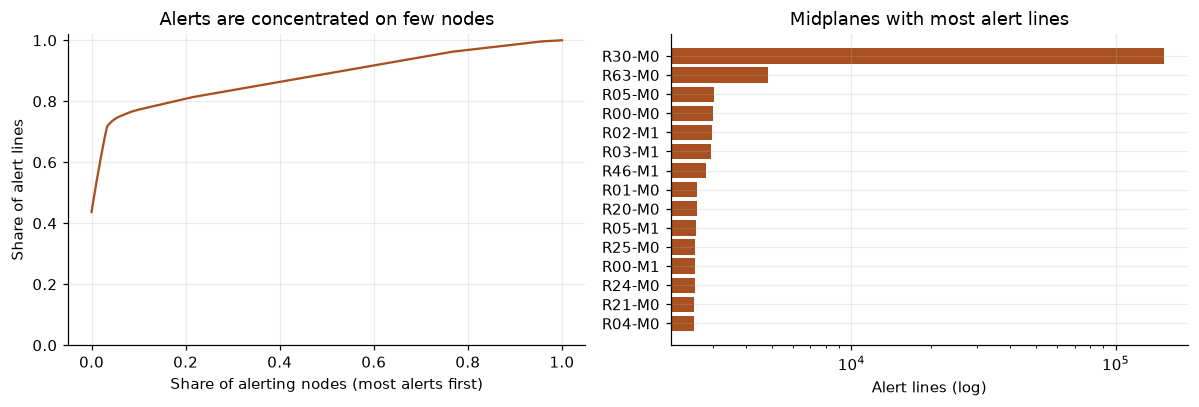

In [7]:
loc = lines["node"].str.extract(r"^(?P<rack>R\d+)(?:-(?P<midplane>M\d+))?")
lines["rack"] = loc["rack"].fillna("other")
lines["midplane"] = (loc["rack"] + "-" + loc["midplane"]).fillna("other")

by_mid = lines.groupby("midplane")["is_anomaly"].agg(lines="size", alerts="sum").sort_values("alerts", ascending=False)
by_mid["alert_rate"] = (by_mid["alerts"] / by_mid["lines"]).round(4)
save_table(by_mid, "midplanes")
display(by_mid.head(15))

node_alerts = lines.loc[lines["is_anomaly"], "node"].value_counts()
cum = node_alerts.cumsum() / node_alerts.sum()
top10_share = float(cum.iloc[min(9, len(cum) - 1)]) if len(cum) else np.nan
KEY["alert_share_top10_nodes"] = round(top10_share, 4)
print(f"{len(node_alerts):,} nodes ever raised an alert; the top 10 produced {top10_share:.1%} of all alert lines")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(np.arange(1, len(cum) + 1) / max(len(cum), 1), cum.values, color=ORANGE)
axes[0].set(xlabel="Share of alerting nodes (most alerts first)", ylabel="Share of alert lines",
            title="Alerts are concentrated on few nodes", ylim=(0, 1.02))
top_mid = by_mid.head(15)[::-1]
axes[1].barh(top_mid.index, top_mid["alerts"], color=ORANGE)
axes[1].set(xscale="log", xlabel="Alert lines (log)", title="Midplanes with most alert lines")
save(fig, "nodes")

## 4. Volume of alerts over time

Chronological split: train until 2005-11-01 00:17, validation until 2005-11-22 22:32, then test


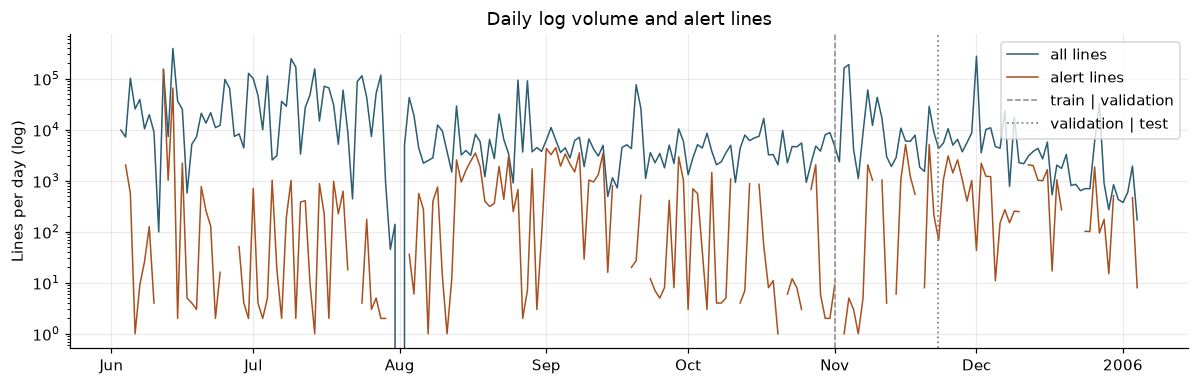

In [8]:
daily = lines.set_index("time").resample("D")["is_anomaly"].agg(["size", "sum"]).rename(
    columns={"size": "lines", "sum": "alerts"})
save_table(daily, "daily")
# Chronological split boundaries, exactly as the pipeline splits: 70/15/15 of the windows in time order
w_start = np.sort(meta["start_ts"].to_numpy())
cut = pd.to_datetime(w_start[int(len(w_start) * TRAIN_FRAC)], unit="s")
cut_test = pd.to_datetime(w_start[int(len(w_start) * (TRAIN_FRAC + VAL_FRAC))], unit="s")
KEY.update({"train_period_ends": str(cut.date()), "test_period_starts": str(cut_test.date())})
print(f"Chronological split: train until {cut:%Y-%m-%d %H:%M}, validation until {cut_test:%Y-%m-%d %H:%M}, then test")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily.index, daily["lines"], color=BLUE, lw=1, label="all lines")
ax.plot(daily.index, daily["alerts"].replace(0, np.nan), color=ORANGE, lw=1, label="alert lines")
ax.axvline(cut, color=GREY, ls="--", lw=1, label="train | validation")
ax.axvline(cut_test, color=GREY, ls=":", lw=1.2, label="validation | test")
ax.set(yscale="log", ylabel="Lines per day (log)", title="Daily log volume and alert lines")
ax.legend()
date_axis(ax)
save(fig, "daily_volume_with_cut")

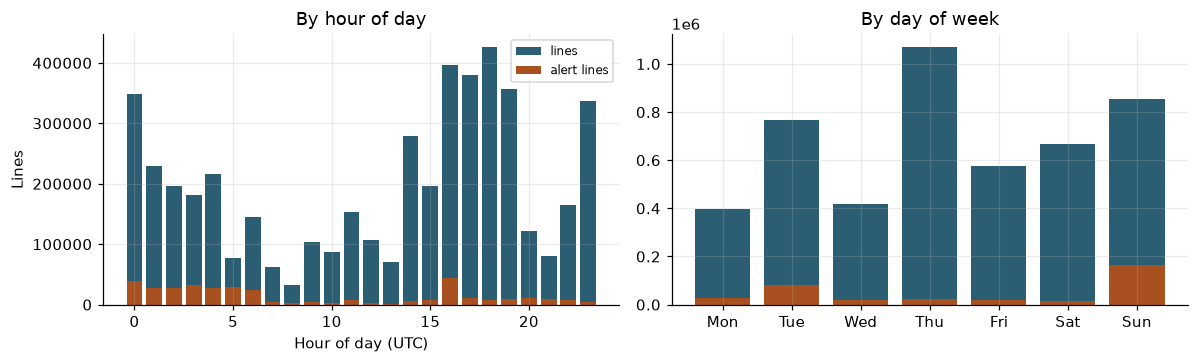

In [9]:
lines["hour"] = lines["time"].dt.hour
lines["weekday"] = lines["time"].dt.day_name().str[:3]
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hour = lines.groupby("hour")["is_anomaly"].agg(lines="size", alerts="sum")
wday = lines.groupby("weekday")["is_anomaly"].agg(lines="size", alerts="sum").reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(hour.index, hour["lines"], color=BLUE, label="lines")
axes[0].bar(hour.index, hour["alerts"], color=ORANGE, label="alert lines")
axes[0].set(xlabel="Hour of day (UTC)", ylabel="Lines", title="By hour of day")
axes[0].legend(fontsize=8)
axes[1].bar(wday.index, wday["lines"], color=BLUE)
axes[1].bar(wday.index, wday["alerts"], color=ORANGE)
axes[1].set(title="By day of week")
save(fig, "hour_weekday")

Mean rate 0.256 lines/s; busiest minute 15,823 lines
Median gap between consecutive alert lines: 0.0 s (share of gaps under 1 s: 87.9%)


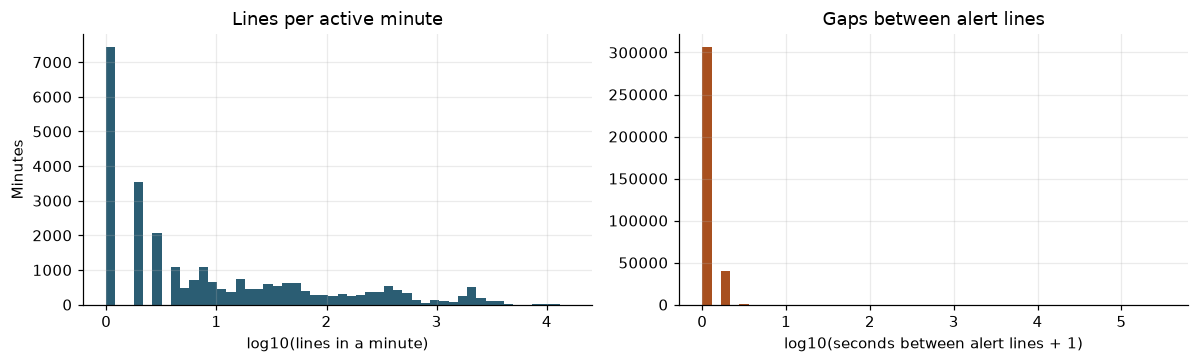

In [10]:
per_min = np.bincount((lines["ts"] - lines["ts"].min()) // 60)
alert_ts = lines.loc[lines["is_anomaly"], "ts"].to_numpy()
gaps = np.diff(alert_ts)
KEY.update({"mean_lines_per_s": round(len(lines) / max(lines["ts"].max() - lines["ts"].min(), 1), 3),
            "peak_lines_per_minute": int(per_min.max()),
            "median_seconds_between_alerts": float(np.median(gaps)) if len(gaps) else np.nan})
print(f"Mean rate {KEY['mean_lines_per_s']} lines/s; busiest minute {per_min.max():,} lines")
print(f"Median gap between consecutive alert lines: {KEY['median_seconds_between_alerts']} s "
      f"(share of gaps under 1 s: {(gaps < 1).mean():.1%})" if len(gaps) else "No alert lines")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
nz = per_min[per_min > 0]
axes[0].hist(np.log10(nz), bins=50, color=BLUE)
axes[0].set(xlabel="log10(lines in a minute)", ylabel="Minutes", title="Lines per active minute")
if len(gaps):
    axes[1].hist(np.log10(gaps + 1), bins=50, color=ORANGE)
axes[1].set(xlabel="log10(seconds between alert lines + 1)", title="Gaps between alert lines")
save(fig, "burstiness")

## 5. Text overview

### 5.1. Message length

normal     alert
chars  count  4399503.0  348460.0
       mean        49.1      45.8
       std         53.0      37.8
       min          0.0      12.0
       25%         21.0      24.0
       50%         26.0      24.0
       75%         44.0      45.0
       max        838.0     185.0
tokens count  4399503.0  348460.0
       mean         4.9       5.3
       std          5.6       2.9
       min          0.0       1.0
       25%          2.0       4.0
       50%          2.0       4.0
       75%          4.0       5.0
       max        142.0      21.0

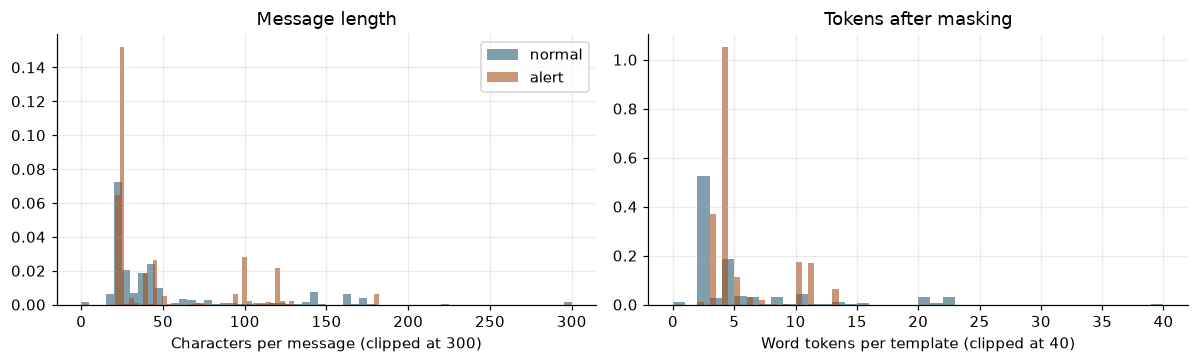

In [11]:
content = pd.read_parquet(INTERIM / "bgl_parsed.parquet", columns=["line_id", "content"]).set_index("line_id")["content"]
lines["chars"] = lines["line_id"].map(content.str.len())
del content
tok_len = templates.set_index("cluster_id")["tokens"].map(len)
lines["tokens"] = lines["cluster_id"].map(tok_len)

length = lines.groupby("is_anomaly")[["chars", "tokens"]].describe().T.round(1)
length.columns = ["normal", "alert"] if length.shape[1] == 2 else length.columns
save_table(length, "message_length")
display(length)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for flag, colr, name in ((False, BLUE, "normal"), (True, ORANGE, "alert")):
    sub = lines[lines["is_anomaly"] == flag]
    axes[0].hist(sub["chars"].clip(upper=300), bins=60, alpha=0.6, color=colr, density=True, label=name)
    axes[1].hist(sub["tokens"].clip(upper=40), bins=40, alpha=0.6, color=colr, density=True, label=name)
axes[0].set(xlabel="Characters per message (clipped at 300)", title="Message length")
axes[1].set(xlabel="Word tokens per template (clipped at 40)", title="Tokens after masking")
axes[0].legend()
save(fig, "message_length")

### 5.2. Tokenisation and lemmatisation

In [12]:
vocab_tok = Counter(t for ts in templates["tokens"] for t in ts)
vocab_lem = Counter(t for ts in templates["lemmas"] for t in ts)
KEY.update({"vocab_tokens": len(vocab_tok), "vocab_lemmas": len(vocab_lem)})
print(f"Template vocabulary: {len(vocab_tok):,} distinct tokens -> {len(vocab_lem):,} distinct lemmas "
      f"({1 - len(vocab_lem) / max(len(vocab_tok), 1):.0%} smaller)")

examples = []
for toks, lems in zip(templates["tokens"], templates["lemmas"]):
    for t in toks:
        if t in lems:
            continue
        cand = [l for l in lems if l[:3] == t[:3] and l != t]
        if cand:
            examples.append((t, cand[0]))
ex = pd.DataFrame(Counter(examples).most_common(20), columns=["token -> lemma", "templates"])
ex["token -> lemma"] = ex["token -> lemma"].map(lambda p: f"{p[0]} -> {p[1]}")
save_table(ex, "lemmatisation_examples", index=False)

Template vocabulary: 638 distinct tokens -> 506 distinct lemmas (21% smaller)


,token -> lemma,templates
0,detected -> detect,27
1,failed -> fail,22
2,asserted -> assert,22
3,corrected -> correct,19
4,expected -> expect,19
5,executing -> execute,18
6,interrupts -> interrupt,13
7,microseconds -> microsecond,12
8,exceptions -> exception,11
9,reading -> read,10


### 5.3. Anomalous vs normal messages

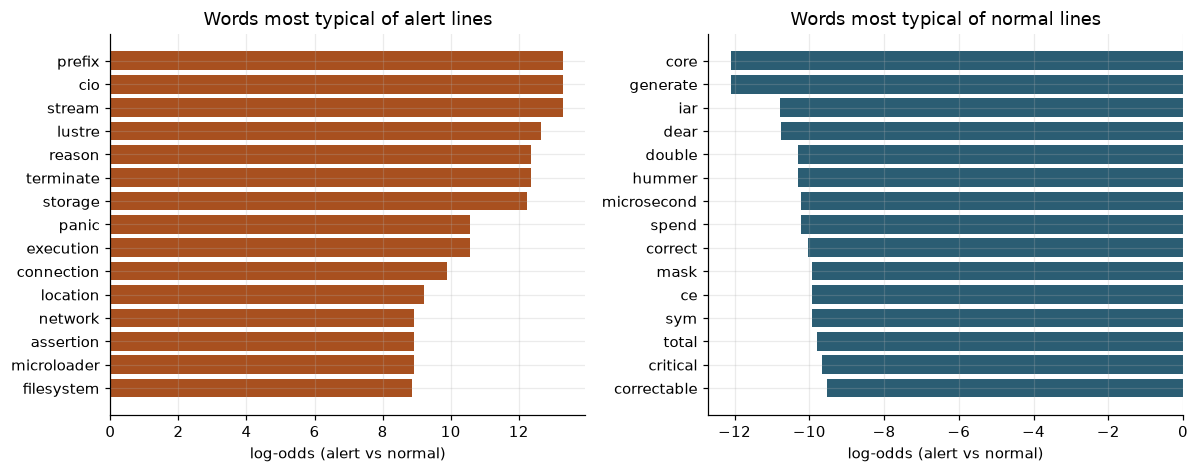

In [13]:
per_tpl = lines.groupby("cluster_id")["is_anomaly"].agg(n_alert="sum", n="size")
per_tpl["n_normal"] = per_tpl["n"] - per_tpl["n_alert"]
lem = templates.set_index("cluster_id")["lemmas"]
w_alert, w_norm = Counter(), Counter()
for cid, row in per_tpl.iterrows():
    for l in set(lem.get(cid, [])):
        w_alert[l] += row["n_alert"]
        w_norm[l] += row["n_normal"]
words = pd.DataFrame({"alert_lines": pd.Series(w_alert), "normal_lines": pd.Series(w_norm)}).fillna(0)
A, N = words["alert_lines"].sum() + 1, words["normal_lines"].sum() + 1
words["log_odds_alert"] = np.log((words["alert_lines"] + 1) / A) - np.log((words["normal_lines"] + 1) / N)
words = words.sort_values("log_odds_alert", ascending=False)
save_table(words, "distinctive_words")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
top_a = words.head(15)[::-1]
top_n = words.tail(15)
axes[0].barh(top_a.index, top_a["log_odds_alert"], color=ORANGE)
axes[0].set(title="Words most typical of alert lines", xlabel="log-odds (alert vs normal)")
axes[1].barh(top_n.index, top_n["log_odds_alert"], color=BLUE)
axes[1].set(title="Words most typical of normal lines", xlabel="log-odds (alert vs normal)")
save(fig, "distinctive_words")

## 6. Drain3 templates

### 6.1. Log concentration

34 of 392 templates cover 90% of all lines; 22 templates occur only once


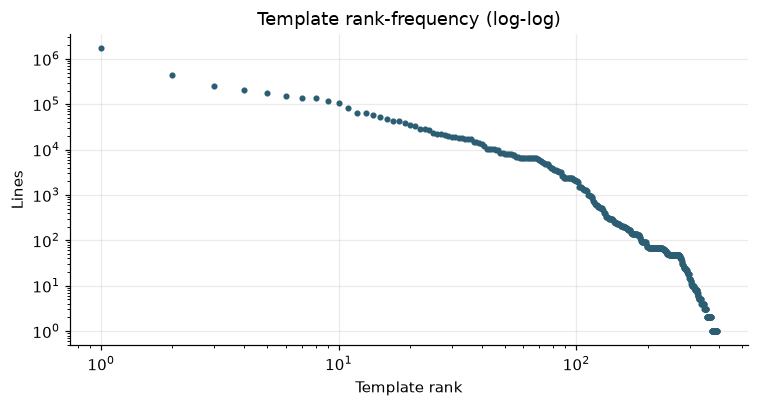

,template,n,n_alert,alert_share
cluster_id,,,,
3,generating core.<NUM>,1706751,0,0.0
265,iar <HEX> dear <HEX>,442966,0,0.0
155,<NUM> floating point alignment exceptions,257317,0,0.0
6,"CE sym <NUM>, at <HEX>, mask <HEX>",201206,0,0.0
12,<NUM> double-hummer alignment exceptions,175184,0,0.0
19,data TLB error interrupt,152734,152734,1.0
378,<NUM> microseconds spent in the rbs signal handler during <NUM> calls. <NUM> microseco...,135090,0,0.0
379,<NUM> total interrupts. <NUM> critical input interrupts. <NUM> microseconds total spen...,135090,0,0.0
156,<HEX> double-hummer alignment exceptions,120580,0,0.0


In [14]:
sizes = per_tpl["n"].sort_values(ascending=False)
cum = sizes.cumsum() / sizes.sum()
k90 = int((cum < 0.9).sum() + 1)
KEY["templates_covering_90pct_lines"] = k90
print(f"{k90} of {len(sizes)} templates cover 90% of all lines; {int((sizes == 1).sum())} templates occur only once")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(np.arange(1, len(sizes) + 1), sizes.values, marker=".", ls="none", color=BLUE)
ax.set(xlabel="Template rank", ylabel="Lines", title="Template rank-frequency (log-log)")
save(fig, "template_rank_frequency")

top_tpl = per_tpl.join(templates.set_index("cluster_id")["template"]).sort_values("n", ascending=False)
top_tpl["alert_share"] = (top_tpl["n_alert"] / top_tpl["n"]).round(3)
save_table(top_tpl[["template", "n", "n_alert", "alert_share"]].head(30), "top_templates")

### 6.2 Are anomalous templates separable by wording alone? (Landauer et al.)

In [15]:
share = per_tpl["n_alert"] / per_tpl["n"]
groups = pd.cut(share, [-0.001, 0, 0.5, 0.999999, 1], labels=["never alert", "mostly normal", "mostly alert", "always alert"])
sep = pd.DataFrame({"templates": groups.value_counts(), "lines": per_tpl.groupby(groups, observed=False)["n"].sum(),
                    "alert_lines": per_tpl.groupby(groups, observed=False)["n_alert"].sum()}).reindex(
    ["never alert", "mostly normal", "mostly alert", "always alert"])
sep["share_of_alert_lines"] = (sep["alert_lines"] / max(sep["alert_lines"].sum(), 1)).round(3)
KEY["alert_lines_in_always_alert_templates"] = float(sep.loc["always alert", "share_of_alert_lines"])
save_table(sep, "template_separability")

,templates,lines,alert_lines,share_of_alert_lines
never alert,337,4379176,0,0.000
mostly normal,6,22573,2729,0.008
mostly alert,4,66805,66322,0.190
always alert,45,279409,279409,0.802


### 6.3. New templates over time (concept drift)

105 templates and 1,388 masked messages first appear after the training period; 22 templates first appear in the test period


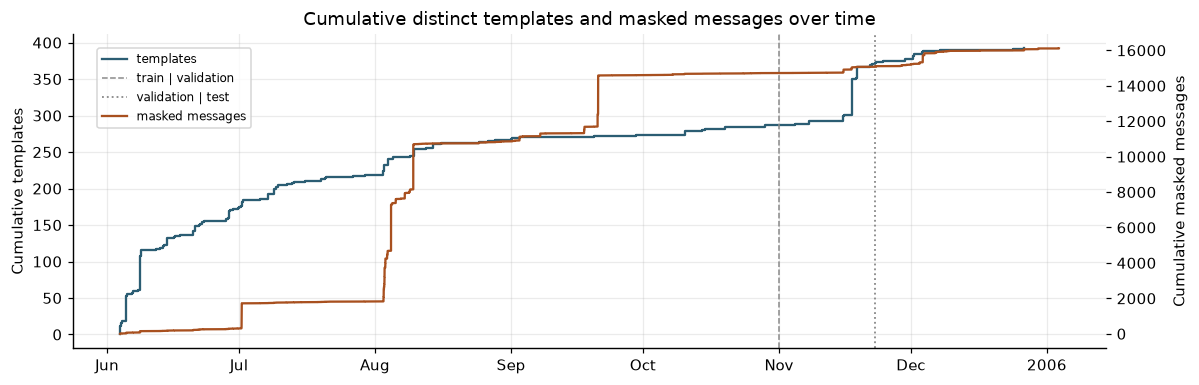

In [16]:
first_seen = lines.groupby("cluster_id")["time"].min().sort_values()
first_msg = lines.groupby("msg_id")["time"].min().sort_values()
unseen_after_cut = int((first_seen > cut).sum())
KEY["templates_first_seen_after_train"] = unseen_after_cut
KEY["masked_messages_first_seen_after_train"] = int((first_msg > cut).sum())
KEY["templates_first_seen_in_test"] = int((first_seen > cut_test).sum())
print(f"{unseen_after_cut} templates and {(first_msg > cut).sum():,} masked messages first appear after the training period; "
      f"{(first_seen > cut_test).sum()} templates first appear in the test period")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.step(first_seen.values, np.arange(1, len(first_seen) + 1), where="post", color=BLUE, label="templates")
ax2 = ax.twinx()
ax2.step(first_msg.values, np.arange(1, len(first_msg) + 1), where="post", color=ORANGE, label="masked messages")
ax.axvline(cut, color=GREY, ls="--", lw=1, label="train | validation")
ax.axvline(cut_test, color=GREY, ls=":", lw=1.2, label="validation | test")
ax.set(ylabel="Cumulative templates", title="Cumulative distinct templates and masked messages over time")
ax2.set_ylabel("Cumulative masked messages")
ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88), fontsize=8)
date_axis(ax)
save(fig, "cumulative_templates")

## 7. Parser-free view (masked messages vs templates)

,value
templates,392.0
masked messages,16107.0
masked messages per template (median),1.0
masked messages per template (max),10084.0
templates with > 1 masked message,115.0
masked messages split across > 1 template,0.0
vocabulary of masked messages (lemmas),672.0


Template with the most distinct masked messages:
   Ido chip status changed: <*> ip=<IP> v=<NUM> t=<NUM> status=M <*> <*> <NUM> <NUM>:<NUM>:<NUM> <*> <NUM>
   - Ido chip status changed: FF:F2:9F:<NUM>:7C:<NUM>:<NUM>:0D:<NUM>:EA:<NUM>:<NUM> ip=<IP> v=<NUM> t=<NUM> status=M Thu Aug 
   - Ido chip status changed: FF:F2:9F:<NUM>:7C:<NUM>:<NUM>:0D:<NUM>:EA:<NUM>:<NUM> ip=<IP> v=<NUM> t=<NUM> status=M Tue Aug 
   - Ido chip status changed: FF:F2:9F:<NUM>:7D:<NUM>:<NUM>:0D:<NUM>:EA:<NUM>:<NUM> ip=<IP> v=<NUM> t=<NUM> status=M Tue Sep 
   - Ido chip status changed: FF:F2:9F:<NUM>:7C:<NUM>:<NUM>:0D:<NUM>:EA:<NUM>:<NUM> ip=<IP> v=<NUM> t=<NUM> status=M Tue Sep 
   - Ido chip status changed: FF:F2:9F:<NUM>:7D:<NUM>:<NUM>:0D:<NUM>:EA:<NUM>:<NUM> ip=<IP> v=<NUM> t=<NUM> status=M Thu Aug 
   - Ido chip status changed: FF:F2:9F:<NUM>:7D:<NUM>:<NUM>:0D:<NUM>:EA:<NUM>:<NUM> ip=<IP> v=<NUM> t=<NUM> status=M Tue Aug 
   - Ido chip status changed: FF:F2:9F:<NUM>:E7:<NUM>:<NUM>:0D:<NUM>:E9:<NUM>:<NUM> ip=<

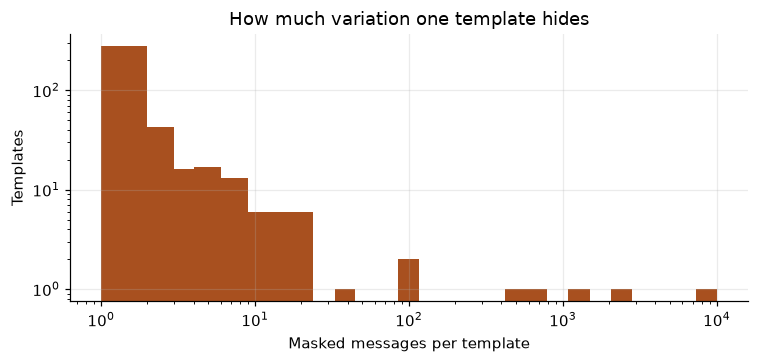

In [17]:
msgs_per_tpl = lines.groupby("cluster_id")["msg_id"].nunique()
tpls_per_msg = lines.groupby("msg_id")["cluster_id"].nunique()
pf = pd.Series({
    "templates": len(templates), "masked messages": len(messages),
    "masked messages per template (median)": float(msgs_per_tpl.median()),
    "masked messages per template (max)": int(msgs_per_tpl.max()),
    "templates with > 1 masked message": int((msgs_per_tpl > 1).sum()),
    "masked messages split across > 1 template": int((tpls_per_msg > 1).sum()),
    "vocabulary of masked messages (lemmas)": len(Counter(t for ts in messages["lemmas"] for t in ts)),
}, name="value").to_frame()
save_table(pf, "parser_free_summary")
display(pf)

worst = msgs_per_tpl.idxmax()
print("Template with the most distinct masked messages:")
print("  ", templates.set_index("cluster_id").loc[worst, "template"])
ids = lines.loc[lines["cluster_id"] == worst, "msg_id"].value_counts().head(8).index
for t in messages.set_index("msg_id").loc[ids, "template"]:
    print("   -", t[:120])

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(msgs_per_tpl, bins=np.unique(np.geomspace(1, max(msgs_per_tpl.max(), 2), 30).astype(int)), color=ORANGE)
ax.set(xscale="log", yscale="log", xlabel="Masked messages per template", ylabel="Templates",
       title="How much variation one template hides")
save(fig, "messages_per_template")

## 8. Windows

### 8.1. 5-minute windows

,value
non-empty windows,14501
anomalous windows,1052
window anomaly rate,7.25%
lines per window (median),6.0
lines per window (95th pct),1040.0
distinct templates per window (median),2.0
alert lines per anomalous window (median),8.0


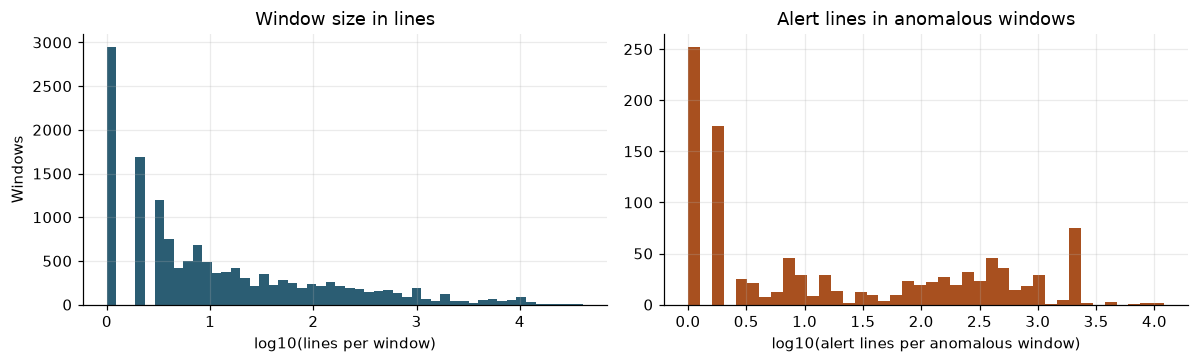

In [18]:
win = pd.Series({
    "non-empty windows": len(meta),
    "anomalous windows": int(meta["label"].sum()),
    "window anomaly rate": f'{meta["label"].mean():.2%}',
    "lines per window (median)": float(meta["n_lines"].median()),
    "lines per window (95th pct)": float(meta["n_lines"].quantile(0.95)),
    "distinct templates per window (median)": float(np.median(np.diff(W_template.indptr))),
    "alert lines per anomalous window (median)": float(meta.loc[meta["label"] == 1, "n_anom_lines"].median()) if meta["label"].any() else np.nan,
}, name="value").to_frame()
KEY.update({"windows": len(meta), "window_anomaly_rate": round(float(meta["label"].mean()), 4)})
save_table(win, "windows_summary")
display(win)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(np.log10(meta["n_lines"]), bins=50, color=BLUE)
axes[0].set(xlabel="log10(lines per window)", ylabel="Windows", title="Window size in lines")
if meta["label"].any():
    axes[1].hist(np.log10(meta.loc[meta["label"] == 1, "n_anom_lines"]), bins=40, color=ORANGE)
axes[1].set(xlabel="log10(alert lines per anomalous window)", title="Alert lines in anomalous windows")
save(fig, "windows")

### 8.2. Window length vs anomaly rate

,window_minutes,non_empty_windows,anomalous_share,median_lines
0,1,27659,0.0654,4.0
1,5,14501,0.0725,6.0
2,15,8590,0.0999,12.0
3,30,5773,0.1313,20.0
4,60,3607,0.1844,49.0


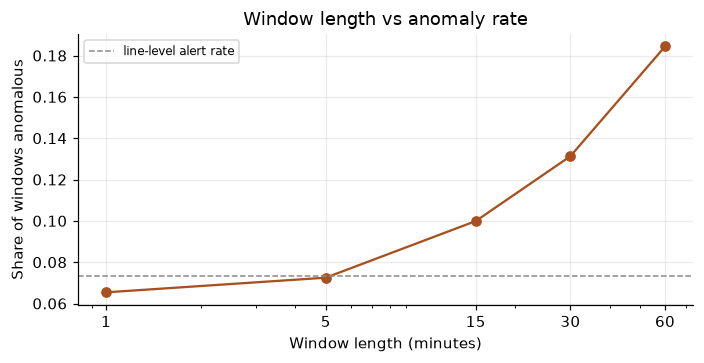

In [19]:
rows = []
t0 = lines["ts"].min()
for minutes in (1, 5, 15, 30, 60):
    bucket = (lines["ts"].to_numpy() - t0) // (minutes * 60)
    n = np.bincount(bucket)
    a = np.bincount(bucket, weights=lines["is_anomaly"].to_numpy().astype(float))
    keep = n > 0
    rows.append({"window_minutes": minutes, "non_empty_windows": int(keep.sum()),
                 "anomalous_share": round(float((a[keep] > 0).mean()), 4),
                 "median_lines": float(np.median(n[keep]))})
wsize = save_table(pd.DataFrame(rows), "window_length_sensitivity", index=False)
display(wsize)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(wsize["window_minutes"], wsize["anomalous_share"], marker="o", color=ORANGE)
ax.axhline(lines["is_anomaly"].mean(), color=GREY, ls="--", lw=1, label="line-level alert rate")
ax.set(xscale="log", xticks=wsize["window_minutes"], xticklabels=wsize["window_minutes"],
       xlabel="Window length (minutes)", ylabel="Share of windows anomalous", title="Window length vs anomaly rate")
ax.legend(fontsize=8)
save(fig, "window_length")

## 9. Chronological vs random split

In [20]:
def make_split(n, mode, seed=SEED):
    order = np.arange(n) if mode == "chronological" else np.random.default_rng(seed).permutation(n)
    s = np.empty(n, dtype=object)
    a, b = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
    s[order[:a]], s[order[a:b]], s[order[b:]] = "train", "val", "test"
    return s

rows = []
y = meta["label"].to_numpy()
for mode in ("chronological", "random"):
    s = make_split(len(meta), mode)
    unseen = np.asarray(W_template[s == "train"].sum(axis=0)).ravel() == 0
    novel = np.asarray(W_template[:, unseen].sum(axis=1)).ravel() > 0
    row = {"split": mode}
    for part in ("train", "val", "test"):
        row[f"{part}_windows"] = int((s == part).sum())
        row[f"{part}_anomaly_rate"] = round(float(y[s == part].mean()), 4)
    row["templates_unseen_in_train"] = int(unseen.sum())
    row["test_windows_with_unseen_template"] = round(float(novel[s == "test"].mean()), 4)
    rows.append(row)
splits = save_table(pd.DataFrame(rows).set_index("split").T, "splits")
splits

split,chronological,random
train_windows,10150.0000,10150.0000
train_anomaly_rate,0.0790,0.0744
val_windows,2175.0000,2175.0000
val_anomaly_rate,0.0432,0.0708
test_windows,2176.0000,2176.0000
test_anomaly_rate,0.0717,0.0657
templates_unseen_in_train,105.0000,17.0000
test_windows_with_unseen_template,0.7477,0.0032


## 10. Summary

In [21]:
key = save_table(pd.Series(KEY, name="value").to_frame(), "key_numbers")
display(key)
print("Figures:", sorted(p.name for p in FIG.glob("eda_*.png")))

,value
lines,4747963
alert_lines,348460
days,214.7
nodes,69252
templates,392
masked_messages,16107
severe_level_precision,0.3525
severe_level_recall,1.0
alert_share_top10_nodes,0.4407
train_period_ends,2005-11-01


Figures: ['eda_alert_categories_top20.png', 'eda_burstiness.png', 'eda_cumulative_templates.png', 'eda_daily_volume_with_cut.png', 'eda_distinctive_words.png', 'eda_hour_weekday.png', 'eda_level_vs_label.png', 'eda_message_length.png', 'eda_messages_per_template.png', 'eda_nodes.png', 'eda_template_rank_frequency.png', 'eda_window_length.png', 'eda_windows.png']
